# Figure 2 · Sample properties

Training, validation, and test distributions over a light-gray parent histogram.
The parent is the full COSMOS2020 catalog with only valid ACS F814W magnitude
< 25. There is no classification, footprint, redshift, size, pixel-quality,
or spatial-buffer cut. Invalid redshift measurements are omitted only from
the redshift histogram; they remain in the parent count.

Set `COSMOS_CATALOG` below, or `SUPERNISP_COSMOS_CATALOG`, to the full FITS catalog.
Missing parent data stops execution before replacing the existing figure.
Only catalog data are read. No models or image mosaics run.


Style revision v06: shared scientific figure style, Matisse-inspired method
colors with redundant line patterns and redundant symbols. Frozen inputs, populations, and numerical values
are retained; the previous executed notebook is archived in `revisions/style_before_v01/`.

The catalog is optional for rendering: a hash-verified cache contains exact integer
histogram counts recovered from the earlier vector export, with all six selected
histograms independently checked against the local catalog rows.


In [1]:
from pathlib import Path
import sys
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from the repository root or from paper_figures/.
here = Path.cwd()
workspace = here if (here / 'figure_utils.py').exists() else here / 'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import (ROOT, FIGURES, DATA, COLORS, style, read_json, export,
                          panel, box, arrow, verified_sources, completed_evaluation,
                          run_inventory, sha)
%matplotlib inline
style()
VERSION = 'v06'
from parent_sample import load_parent, valid_values, probability_density
from figure_utils import MARKERS, INK, GRID, ESTIMATOR_COLORS, finish_axes


In [2]:
# Review controls: figure size, histogram bins, colors, export version.
FIGSIZE = (7.2, 2.8)
# Edit this path on your catalog/mosaic machine, if it is not at the default.
COSMOS_CATALOG = Path(os.environ.get('SUPERNISP_COSMOS_CATALOG',
    str(ROOT / 'catalog/COSMOS2020_CLASSIC_R1_v2.2_p3.fits'))).expanduser()
PARENT_COLOR = '#BDBDBD'
PARENT_MAG_LIMIT = 25.
# Explicit missing-value codes; verify these if using a different catalog release.
CATALOG_SENTINELS = (-99, 99, -999, 999)
# Show the population beyond the sample cuts. Tails outside these axes retain
# their probability: do not renormalize the parent to only the displayed interval.
MAG_BINS = np.linspace(16, PARENT_MAG_LIMIT, 28)
REDSHIFT_BINS = np.linspace(0, 6, 51)
UPDATE_PAPER = False  # After successful export, install the PDF and update its caption.
PROPERTY_SPLITS = ['train', 'validation', 'test']
PROPERTY_COLORS = {k:COLORS[k] for k in ['train','validation','test']}
manifest_path = DATA / 'manifest.json'
objects_path = DATA / 'objects.csv'
manifest = read_json(manifest_path)
objects = pd.read_csv(objects_path)
assert len(objects) == manifest['accepted']
assert objects.id_classic.is_unique and objects.row.is_unique
assert objects.groupby('split').size().to_dict() == manifest['split_counts']
assert manifest['accepted'] + sum(manifest['rejection_counts'].values()) == manifest['candidates']
display(pd.DataFrame({'split': list(manifest['split_counts']),
                      'galaxies': list(manifest['split_counts'].values())}))
print('Selection:', manifest['selection'])
print('Quality:', manifest['quality'])

,split,galaxies
0,train,17816
1,test,2876
2,validation,2118


Selection: lp_type==0; ACS_F814W_MAG<25; .01<ez_z_phot<3; 4<FLUX_RADIUS<500; existing dated coverage candidates
Quality: DQ==0; finite SCI and positive finite RMS<1e7; >=95% coverage each instrument; central 5x5 NISP /25x25 HR fully valid


In [3]:
hist_cache_path=FIGURES/'inputs/parent_histograms_v05.json'
hist_cache=read_json(hist_cache_path)
assert hist_cache['complete'] and hist_cache['selected_histograms_independently_reproduced']==6
assert sha(ROOT/hist_cache['source_svg'])==hist_cache['source_svg_sha256']
assert sha(objects_path)==hist_cache['objects_sha256']
parent_metadata=read_json(FIGURES/'inputs/parent_sample_v05.json')
assert sha(FIGURES/'inputs/parent_sample_v05.json')==hist_cache['source_metadata_sha256']
print('Using exact cached histogram counts; original catalog SHA:',hist_cache['original_catalog_sha256'])


Using exact cached histogram counts; original catalog SHA: 42ea2f1b2ac12fbd9ab199b631909e010b7811fdf353b0e89f3c4e8ccef6c5c1


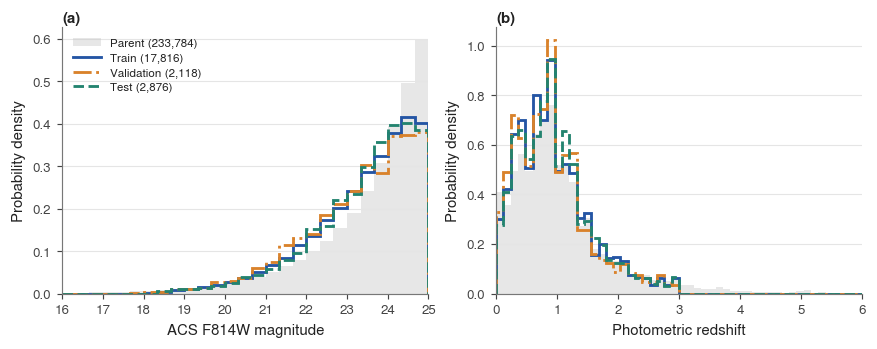

In [4]:
fig,axes=plt.subplots(1,2,figsize=FIGSIZE,layout='constrained')
mag_bins,z_bins=MAG_BINS,REDSHIFT_BINS
histogram_accounting={}
for ax,column,bins,xlabel,letter in [
    (axes[0],'ACS_F814W_MAG',mag_bins,'ACS F814W magnitude','a'),
    (axes[1],'ez_z_phot',z_bins,'Photometric redshift','b')]:
    frozen=hist_cache['histograms'][column]
    np.testing.assert_array_equal(bins,frozen['bins'])
    histogram_accounting[column]={}
    for name in ['parent',*PROPERTY_SPLITS]:
        rec=frozen['populations'][name]
        counts=np.array(rec['counts'])
        if name!='parent':
            values=valid_values(objects[objects.split==name],column,CATALOG_SENTINELS)
            np.testing.assert_array_equal(counts,np.histogram(values,bins)[0])
        density=counts/(rec['valid_measurements']*np.diff(bins))
        histogram_accounting[column][name]={k:v for k,v in rec.items() if k!='counts'}
        if name=='parent':
            ax.stairs(density,bins,fill=True,color=PARENT_COLOR,alpha=.35,lw=0,
                      label=f"Parent ({rec['objects']:,})",zorder=0)
        else:
            ax.stairs(density,bins,lw=1.7,color=PROPERTY_COLORS[name],
                      ls={'train':'-','validation':'-.','test':'--'}[name],
                      label=f"{name.capitalize()} ({rec['objects']:,})",zorder=2)
    ax.set(xlabel=xlabel,ylabel='Probability density',xlim=(bins[0],bins[-1]))
    ax.text(0,1.02,f'({letter})',transform=ax.transAxes,fontsize=9,fontweight='bold')
    finish_axes(ax,grid='y')
axes[0].legend(frameon=False,loc='upper left',fontsize=7)
plt.show()


In [5]:
paths=export(fig,f'fig02_sample_properties_{VERSION}','02_sample_properties.ipynb',
    [manifest_path,objects_path,hist_cache_path,FIGURES/'inputs/parent_sample_v05.json'],
    dict(figsize=FIGSIZE,property_splits=PROPERTY_SPLITS,colors=PROPERTY_COLORS,
         parent_color=PARENT_COLOR,legend='left panel only',magnitude_bins=mag_bins.tolist(),
         redshift_bins=z_bins.tolist(),histogram_accounting=histogram_accounting,
         normalization='All valid measurements including tails outside axes',
         parent=parent_metadata,counts_source='Verified integer counts from frozen v05 SVG',
         test_access='Catalog properties only; no images or performance evaluation'),
    status='Figure 2 style revision; identical histogram counts and sample')


Exported: fig02_sample_properties_v06.pdf, fig02_sample_properties_v06.svg, fig02_sample_properties_v06.png


## Working caption

Optical-magnitude (a) and photometric-redshift (b) distributions of the matched
training (17,816), validation (2,118) and reserved-test (2,876) samples. Gray shading shows the full COSMOS2020 parent catalog with only valid ACS
F814W magnitude < 25. No classification, footprint, redshift, size, or quality
cuts are applied to the parent. Invalid redshifts are omitted only from the
redshift histogram; they remain in the parent count. Histograms use common bins and are normalized
by all valid measurements per quantity and population, including tails outside
the displayed ranges. Legend counts are total objects; invalid measurements
and out-of-range counts are reported in the table above.
Training is blue/solid, validation orange/dash-dot, and test green/dashed. The ACS F814W magnitude cut is 25, and
the selected photometric-redshift range is 0.01–3. The sample is optically
selected, not a NISP-complete galaxy sample.

## How the splits are used

- **Training:** optimizer updates and fitting the fixed normalization scales.
- **Validation:** development, checkpoint selection, architecture comparisons,
  and refinement of the observed-shape measurement protocol. Residual runs
  select checkpoints by masked MAE on all 2,118 validation objects; diffusion
  uses generated physical MAE on a fixed 256-object monitor, followed by the
  full 2,118-object validation analysis. Current shape comparisons are therefore
  development results, not final held-out performance estimates.
- **Test:** reserved for final reconstruction and observed-shape evaluation
  after the models, checkpoints, measurement settings, masks and reporting
  choices are frozen. Do not retune those choices based on test results.

Splits use disjoint 3-arcmin sky blocks, with 10-arcsec boundary buffers rather
than an independent random split of neighboring galaxies. This reduces local
spatial leakage, but all splits are in COSMOS and do not establish generalization
to another field. This figure reads test catalog properties only; no test images
or model outputs are accessed. These histograms describe the fixed split and
must not be used to reshuffle it or tune the models to the test distribution.
